In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

In [2]:
data = pd.read_csv('Dataset_ecommerce.csv')
data.head()

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country
0,536365,2010-12-01 08:26:00,17850.0,SC1734,Electronics,65,10.23,Egypt
1,536365,2010-12-01 08:26:00,17850.0,SC2088,Furniture,95,19.61,Mali
2,536365,2010-12-01 08:26:00,17850.0,SC3463,Books,78,61.49,Mali
3,536365,2010-12-01 08:26:00,17850.0,SC6228,Toys,15,24.73,South Africa
4,536365,2010-12-01 08:26:00,17850.0,SC2149,Toys,50,38.83,Rwanda


In [3]:
data.shape

(541909, 8)

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   InvoiceDate  541909 non-null  str    
 2   CustomerID   406829 non-null  float64
 3   StockCode    541909 non-null  str    
 4   Description  541909 non-null  str    
 5   Quantity     541909 non-null  int64  
 6   UnitPrice    541909 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [5]:
data.describe(include = 'all')

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country
count,541909,541909,406829.000000,541909,541909,541909.000000,541909.000000,541909
unique,25900,23260,NaN,9000,10,NaN,NaN,28
top,573585,2011-10-31 14:41:00,NaN,SC2014,Sports Equipment,NaN,NaN,Cote d'Ivoire
freq,1114,1114,NaN,96,54765,NaN,NaN,19651
mean,NaN,NaN,15287.690570,NaN,NaN,50.534748,50.476354,NaN
std,NaN,NaN,1713.600303,NaN,NaN,28.849367,28.564775,NaN
min,NaN,NaN,12346.000000,NaN,NaN,1.000000,1.000000,NaN
25%,NaN,NaN,13953.000000,NaN,NaN,26.000000,25.750000,NaN
50%,NaN,NaN,15152.000000,NaN,NaN,51.000000,50.430000,NaN
75%,NaN,NaN,16791.000000,NaN,NaN,76.000000,75.180000,NaN


In [6]:
data.isnull().sum()

InvoiceNo           0
InvoiceDate         0
CustomerID     135080
StockCode           0
Description         0
Quantity            0
UnitPrice           0
Country             0
dtype: int64

In [8]:
data.duplicated().sum()

np.int64(0)

In [21]:
#checking categorical data for inconsistency
cat_features = ['Description','Country']
for column in cat_features:
    print(column)
    print(data[column].unique())

Description
<StringArray>
[     'Electronics',        'Furniture',            'Books',
             'Toys',      'Kitchenware',        'Cosmetics',
 'Sports Equipment',            'Shoes',           'Cloths',
          'Jewelry']
Length: 10, dtype: str
Country
<StringArray>
[        'Egypt',          'Mali',  'South Africa',        'Rwanda',
  'Sierra Leone',         'Benin',  'Burkina Faso',       'Nigeria',
 'Cote d'Ivoire',       'Somalia',      'Cameroon',      'Tanzania',
         'Sudan',    'Madagascar',       'Tunisia',    'Mozambique',
      'Zimbabwe',        'Uganda',         'Libya',       'Morocco',
      'Ethiopia',       'Algeria',         'Ghana',         'Niger',
          'Togo',         'Kenya',        'Zambia',       'Senegal']
Length: 28, dtype: str


In [22]:
#checking nuerical features for incorrect, imposible and unsual values
numeric_data = data.select_dtypes(include='number').drop(
    columns=['CustomerID'], errors='ignore'
)

Q1 = numeric_data.quantile(0.25)
Q3 = numeric_data.quantile(0.75)
IQR = Q3 - Q1

summary = numeric_data.describe().T

summary['IQR'] = IQR
summary['Lower_Bound'] = Q1 - 1.5 * IQR
summary['Upper_Bound'] = Q3 + 1.5 * IQR

summary['Outlier_Count'] = (
    (numeric_data.lt(summary['Lower_Bound'], axis=1)) |
    (numeric_data.gt(summary['Upper_Bound'], axis=1))
).sum()

summary['Zero_Count'] = (numeric_data == 0).sum()
summary['Negative_Count'] = (numeric_data < 0).sum()

summary['Above_Upper_Bound'] = (
    numeric_data.gt(summary['Upper_Bound'], axis=1)
).sum()

display(summary) #checking for incorrect, imposible, unsual values


,count,mean,std,min,25%,50%,75%,max,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Zero_Count,Negative_Count,Above_Upper_Bound
Quantity,541909.0,50.534748,28.849367,1.0,26.00,51.00,76.00,100.0,50.00,-49.000,151.000,0,0,0,0
UnitPrice,541909.0,50.476354,28.564775,1.0,25.75,50.43,75.18,100.0,49.43,-48.395,149.325,0,0,0,0


In [23]:
data.isnull().sum()

InvoiceNo           0
InvoiceDate         0
CustomerID     135080
StockCode           0
Description         0
Quantity            0
UnitPrice           0
Country             0
dtype: int64

In [24]:
data.isnull().mean() * 100

InvoiceNo       0.000000
InvoiceDate     0.000000
CustomerID     24.926694
StockCode       0.000000
Description     0.000000
Quantity        0.000000
UnitPrice       0.000000
Country         0.000000
dtype: float64

In [25]:
data.dropna(inplace = True)

In [26]:
data.isnull().mean() * 100

InvoiceNo      0.0
InvoiceDate    0.0
CustomerID     0.0
StockCode      0.0
Description    0.0
Quantity       0.0
UnitPrice      0.0
Country        0.0
dtype: float64

### Exploratory Data Analysis

#### Numerical Distribution

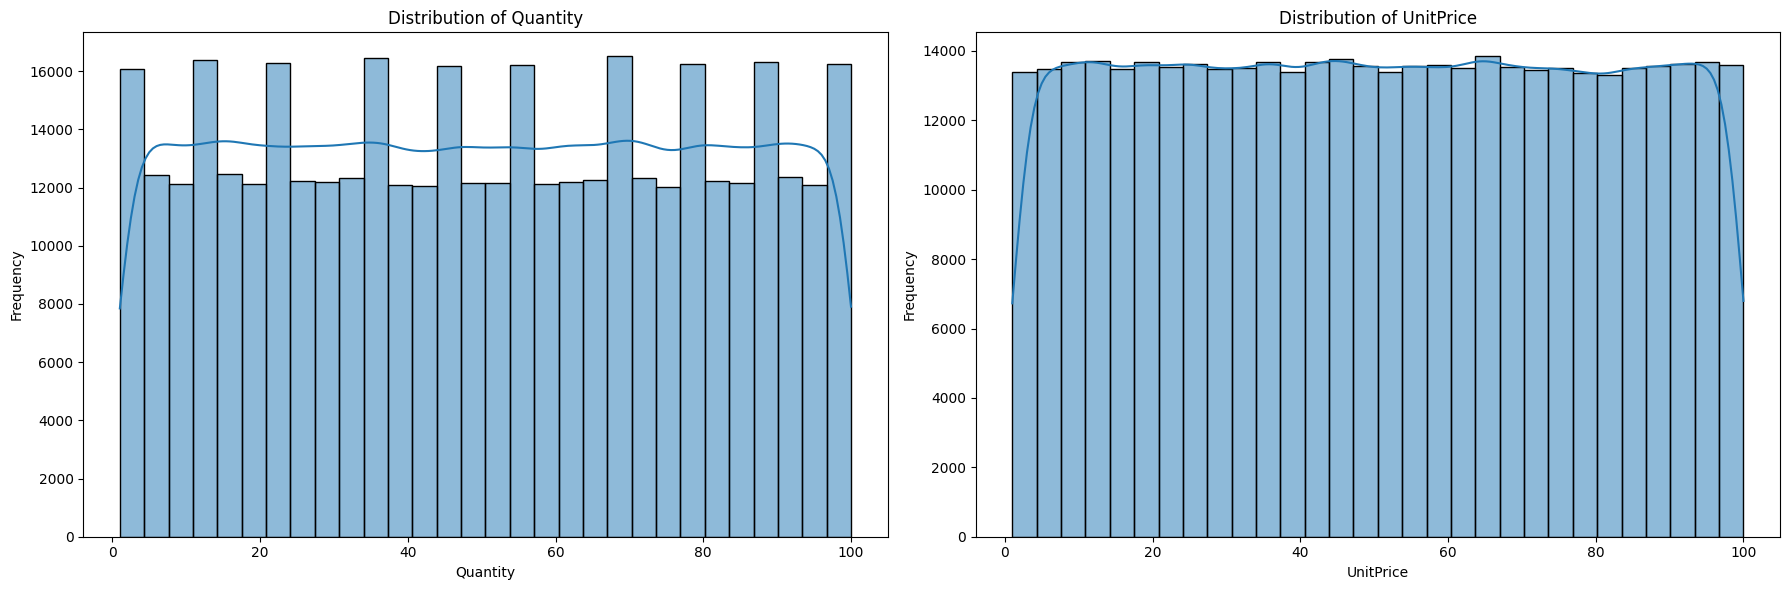

In [28]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize =(18, 6))
ax = ax.flatten()
sns.histplot(data = data, x = 'Quantity', bins = 30, kde = True, ax = ax[0])
ax[0].set_title('Distribution of Quantity')
ax[0].set_xlabel('Quantity')
ax[0].set_ylabel('Frequency');

sns.histplot(data = data, x = 'UnitPrice', bins = 30, kde = True, ax = ax[1])
ax[1].set_title('Distribution of UnitPrice')
ax[1].set_xlabel('UnitPrice')
ax[1].set_ylabel('Frequency')
plt.tight_layout()
plt.show()

In [32]:
data[['UnitPrice','Quantity' ]].skew()

UnitPrice    0.002824
Quantity     0.001222
dtype: float64

#### Categorical Analysis

##### Univariant Analysis

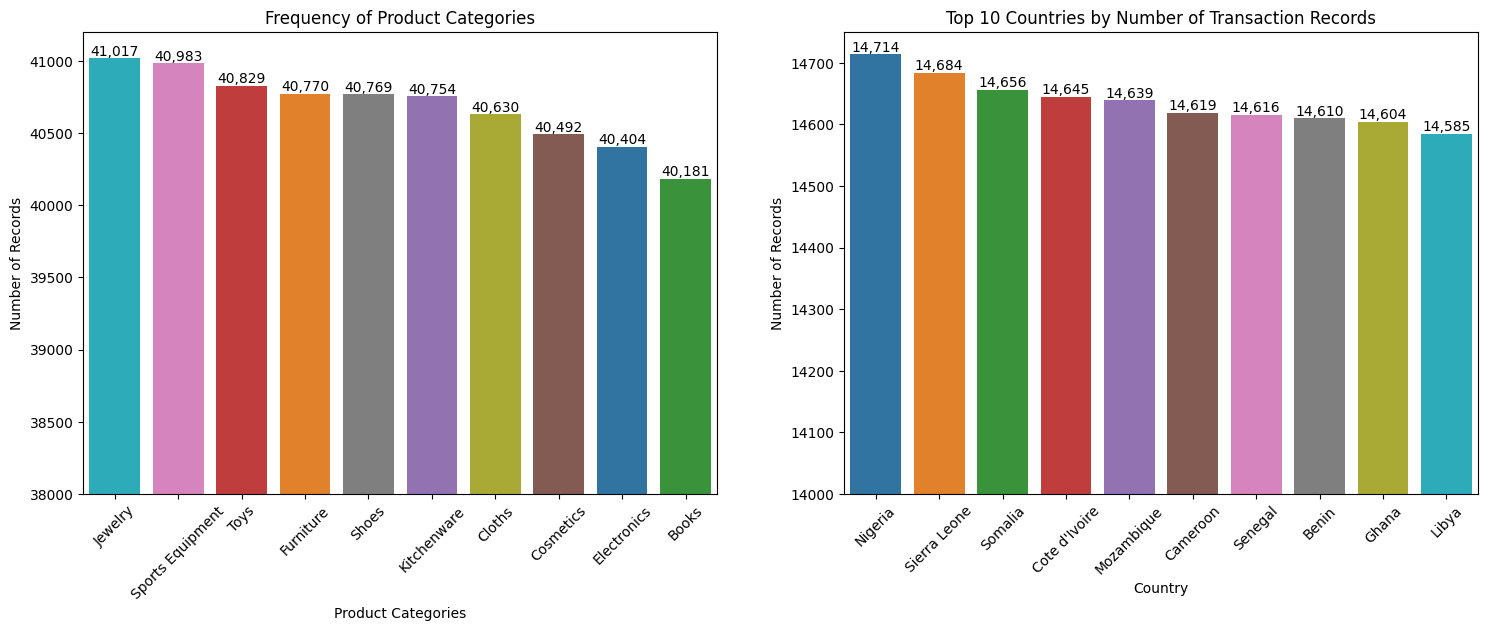

In [33]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (18,6))
ax = ax.flatten()
sns.countplot(x = 'Description', data = data, ax = ax[0], hue = 'Description', order = data['Description'].value_counts().index)
ax[0].tick_params(axis = 'x', rotation = 45)
ax[0].set_ylim(38000, 41200)
ax[0].set_title('Frequency of Product Categories')
ax[0].set_ylabel('Number of Records')
ax[0].set_xlabel('Product Categories')
for c in ax[0].containers:
    ax[0].bar_label(c,fmt = lambda x: f'{x:,.0f}')

top10_country_count =  data['Country'].value_counts().head(10).reset_index()
sns.barplot(x = 'Country', y = 'count',data = top10_country_count, ax = ax[1], hue = 'Country')
ax[1].tick_params(axis = 'x', rotation = 45)
ax[1].set_ylim(14000, 14750)
ax[1].set_title('Top 10 Countries by Number of Transaction Records')
ax[1].set_ylabel('Number of Records')
ax[1].set_xlabel('Country')
for c in ax[1].containers:
    ax[1].bar_label(c, fmt = lambda x: f'{x:,.0f}')


##### Bivirant Analysis

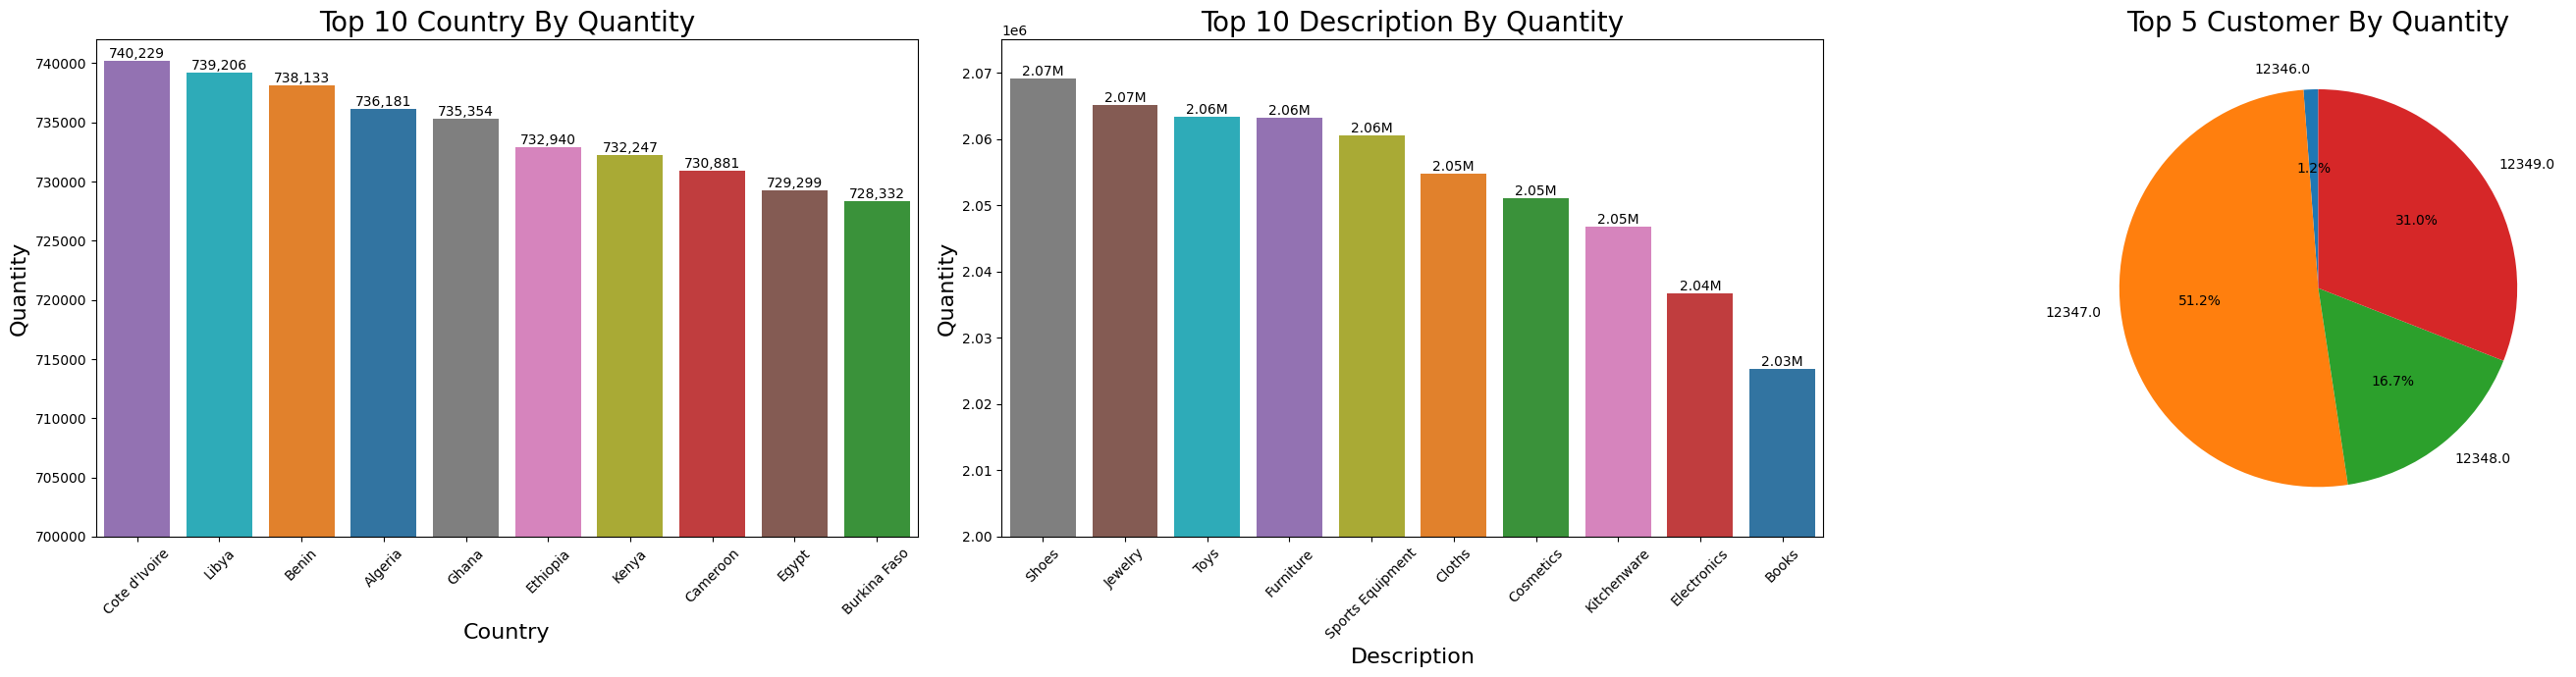

In [34]:
fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = (28,7))
ax = ax.flatten()
Top10_Country_by_Quantity = data.groupby('Country')['Quantity'].sum().head(10).reset_index()
sns.barplot(x = 'Country', y = 'Quantity', data = Top10_Country_by_Quantity , hue = 'Country',
            ax = ax[0], order = Top10_Country_by_Quantity.sort_values('Quantity', ascending = False)['Country']
           )
ax[0].tick_params(axis = 'x', rotation = 45)
ax[0].set_ylim(700000,742000)
ax[0].set_xlabel('Country',fontsize = 16)
ax[0].set_ylabel('Quantity',fontsize = 16)
ax[0].set_title('Top 10 Country By Quantity', fontsize = 20)
for c in ax[0].containers:
    ax[0].bar_label(c, fmt = lambda x:f'{x:,.0f}')

Top10_Description_by_Quantity = data.groupby('Description')['Quantity'].sum().head(10).reset_index()
sns.barplot(x = 'Description', y = 'Quantity', data = Top10_Description_by_Quantity, hue = 'Description',
            ax = ax[1], order = Top10_Description_by_Quantity.sort_values('Quantity', ascending = False)['Description']
           )
ax[1].tick_params(axis = 'x', rotation = 45)
ax[1].set_ylim(2000000,2075000)
ax[1].set_xlabel('Description',fontsize = 16)
ax[1].set_ylabel('Quantity',fontsize = 16)
ax[1].set_title('Top 10 Description By Quantity', fontsize = 20)
for c in ax[1].containers:
    ax[1].bar_label(c, fmt = lambda x: f'{x/1000000:.2f}M')


Top4_Customers_by_Quantity = data.groupby('CustomerID').nunique()['Quantity'].head(4).reset_index()

ax[2].pie(Top4_Customers_by_Quantity['Quantity'],
          labels = Top4_Customers_by_Quantity['CustomerID'],
          autopct = '%1.1f%%',
          startangle = 90
         )         
ax[2].set_title('Top 5 Customer By Quantity', fontsize = 20)
plt.tight_layout()
plt.show()   

#### Sales Trend

In [37]:
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])
print(f'Earlest Date = {data['InvoiceDate'].min()}')
print(f'Latest Date = {data['InvoiceDate'].max()}')

Earlest Date = 2010-12-01 08:26:00
Latest Date = 2011-12-09 12:50:00


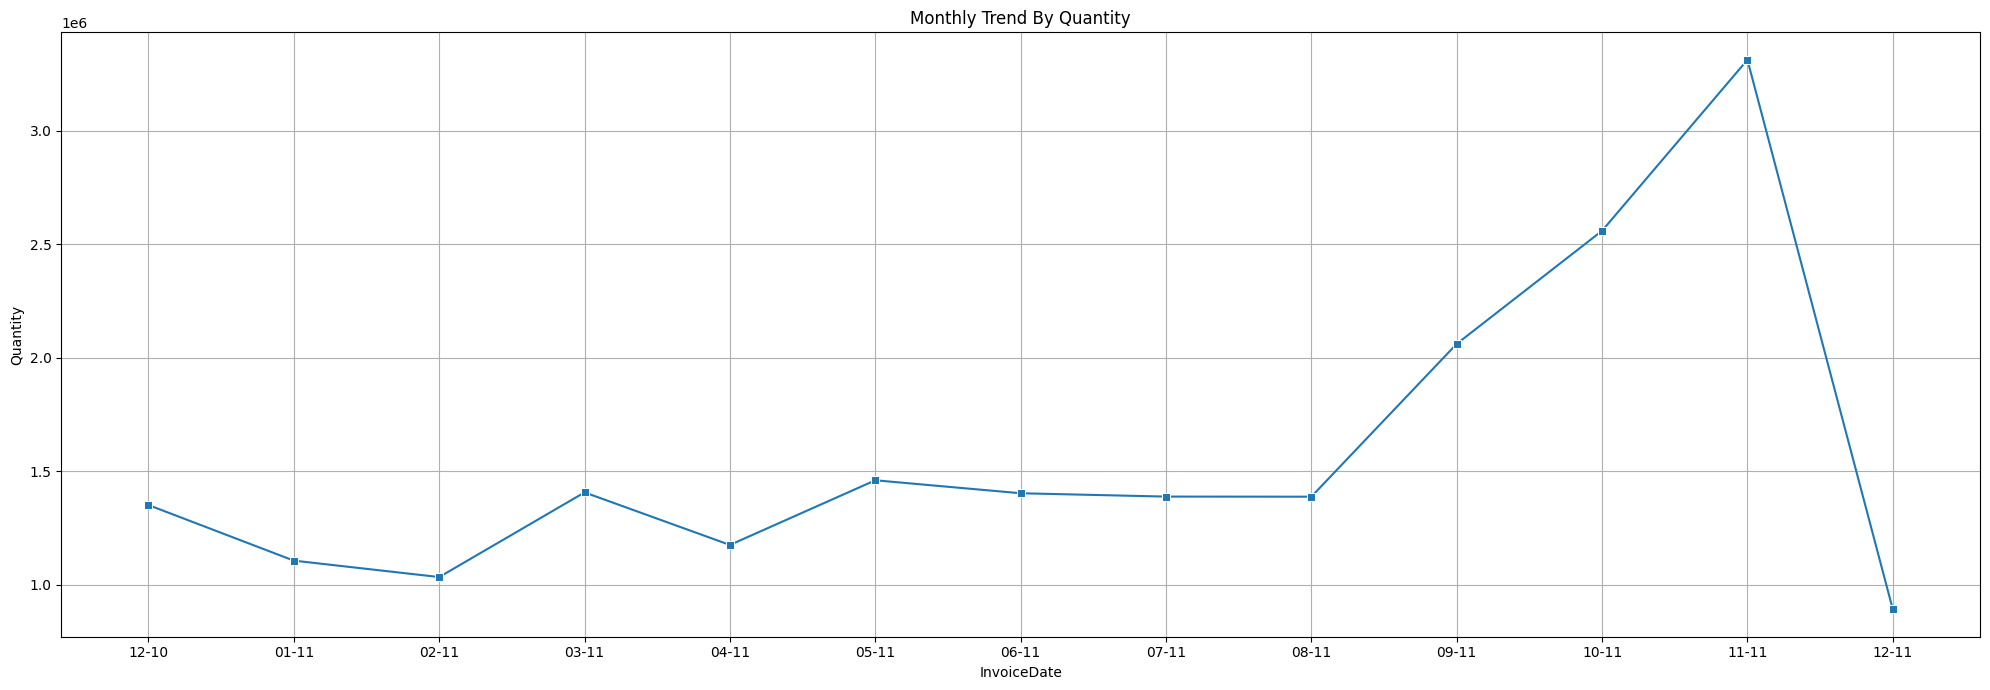

In [38]:
Monthly_trend = data.groupby(data['InvoiceDate'].dt.to_period('M'))['Quantity'].sum()
plt.figure(figsize = (20,7))
sns.lineplot(x = Monthly_trend.index.strftime('%m-%y'), y=  Monthly_trend.values, marker = 's')
plt.grid()
plt.title('Monthly Trend By Quantity')
plt.xlabel('InvoiceDate')
plt.ylabel('Quantity')
plt.tight_layout()
plt.show()

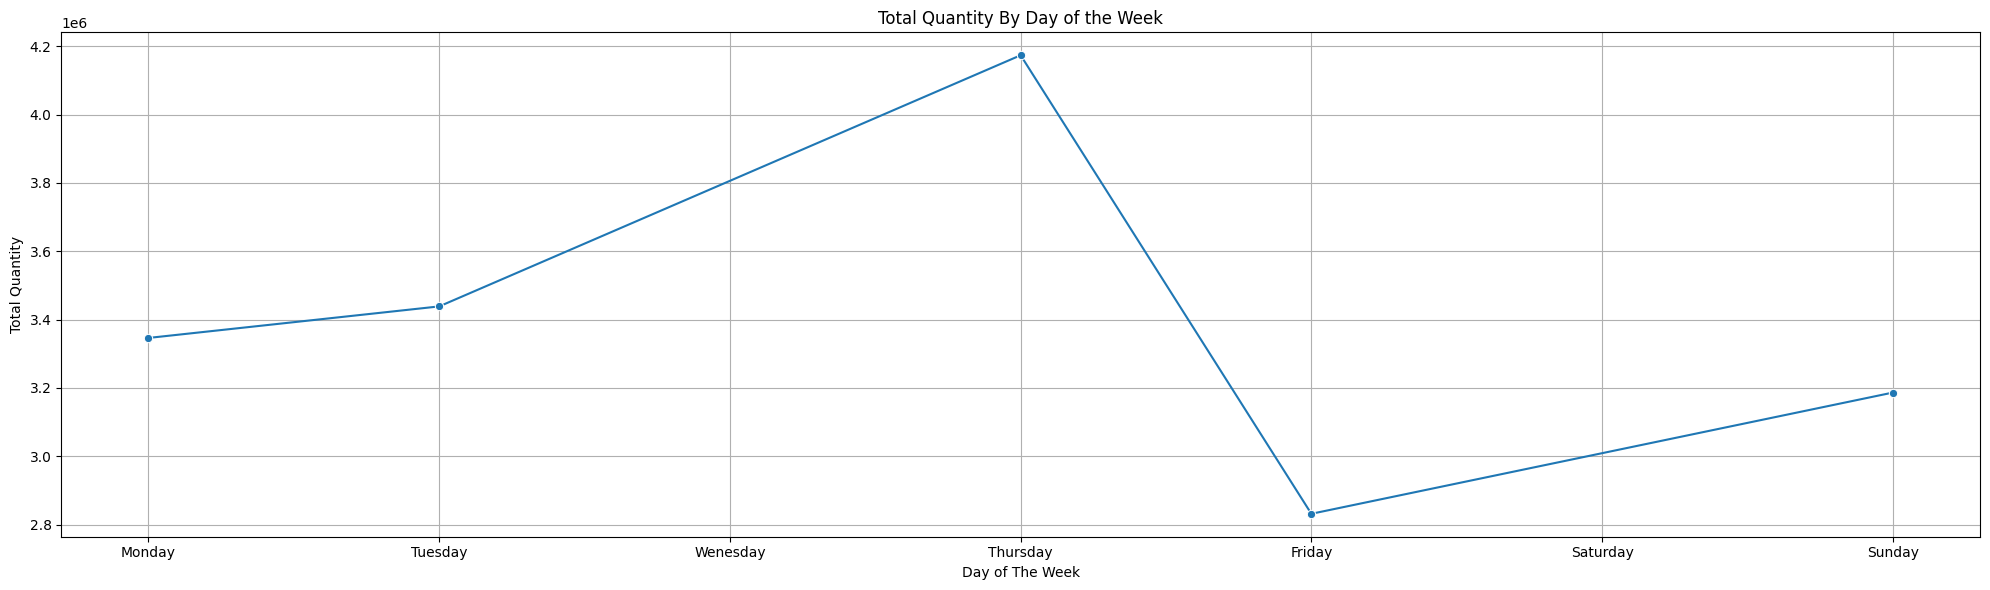

In [39]:
Daily_trend = data.groupby(data['InvoiceDate'].dt.day_name())['Quantity'].sum()
Daily_trend = Daily_trend.reindex(['Monday','Tuesday','Wenesday','Thursday','Friday','Saturday','Sunday'])
plt.figure(figsize = (20,6))
plt.grid()
sns.lineplot(x= Daily_trend.index, y= Daily_trend.values,marker = 'o' )
plt.title('Total Quantity By Day of the Week')
plt.xlabel('Day of The Week')
plt.ylabel('Total Quantity')
plt.tight_layout()
plt.show()

#### Cohort Analysis

In [41]:
data['InvoiceMonths'] = data['InvoiceDate'].dt.to_period('M')

In [47]:
data['CohortMonth'] = data.groupby('CustomerID')['InvoiceMonths'].transform('min')


In [52]:
data['Cohortindex'] = ((data['InvoiceMonths'].dt.year - data['CohortMonth'].dt.year) * 12 +
(data['InvoiceMonths'].dt.month - data['CohortMonth'].dt.month)+1)

In [53]:
data.tail()

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country,InvoiceMonths,CohortMonth,Cohortindex
541904,581587,2011-12-09 12:50:00,12680.0,SC5440,Furniture,25,36.53,Mozambique,2011-12,2011-08,5
541905,581587,2011-12-09 12:50:00,12680.0,SC3576,Cloths,94,90.65,Tunisia,2011-12,2011-08,5
541906,581587,2011-12-09 12:50:00,12680.0,SC5283,Furniture,14,40.07,Somalia,2011-12,2011-08,5
541907,581587,2011-12-09 12:50:00,12680.0,SC1099,Cosmetics,45,79.83,Senegal,2011-12,2011-08,5
541908,581587,2011-12-09 12:50:00,12680.0,SC9276,Toys,6,46.62,Ethiopia,2011-12,2011-08,5


##### Cohort Table

In [65]:
cohortInfo = data.groupby(['CohortMonth','Cohortindex'])['CustomerID'].nunique().reset_index()
cohortInfo.rename(columns = {'CustomerID':'Number of Customers'}, inplace = True)
cohortInfo

,CohortMonth,Cohortindex,Number of Customers
0,2010-12,1,948
1,2010-12,2,362
2,2010-12,3,317
3,2010-12,4,367
4,2010-12,5,341
...,...,...,...
86,2011-10,2,93
87,2011-10,3,46
88,2011-11,1,321
89,2011-11,2,43


In [73]:
cohortTable = cohortInfo.pivot(index = 'CohortMonth', columns = 'Cohortindex', values = 'Number of Customers' )
cohortTable.index = cohortTable.index.strftime('%B - %Y') 
cohortTable

Cohortindex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
December - 2010,948.0,362.0,317.0,367.0,341.0,376.0,360.0,336.0,336.0,374.0,354.0,474.0,260.0
January - 2011,421.0,101.0,119.0,102.0,138.0,126.0,110.0,108.0,131.0,146.0,155.0,63.0,NaN
February - 2011,380.0,94.0,73.0,106.0,102.0,94.0,97.0,107.0,98.0,119.0,35.0,NaN,NaN
March - 2011,440.0,84.0,112.0,96.0,102.0,78.0,116.0,105.0,127.0,39.0,NaN,NaN,NaN
April - 2011,299.0,68.0,66.0,63.0,62.0,71.0,69.0,78.0,25.0,NaN,NaN,NaN,NaN
May - 2011,279.0,66.0,48.0,48.0,60.0,68.0,74.0,29.0,NaN,NaN,NaN,NaN,NaN
June - 2011,235.0,49.0,44.0,64.0,58.0,79.0,24.0,NaN,NaN,NaN,NaN,NaN,NaN
July - 2011,191.0,40.0,39.0,44.0,52.0,22.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
August - 2011,167.0,42.0,42.0,42.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


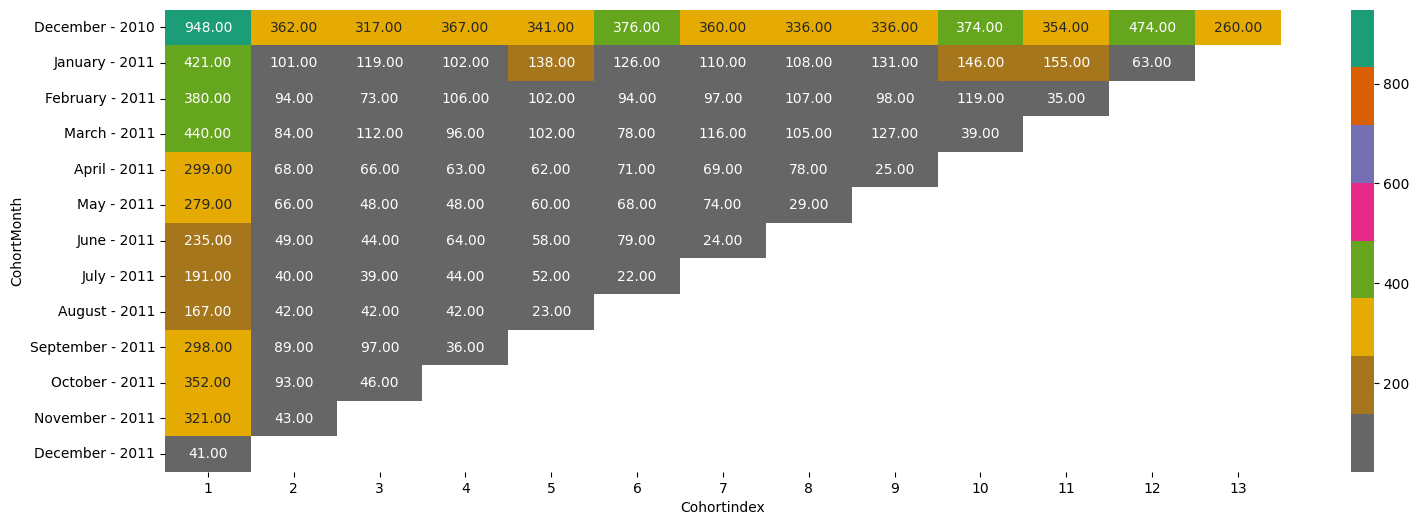

In [82]:
plt.figure(figsize = (18,6))
sns.heatmap(cohortTable, annot = True, fmt = '.2f', cmap = 'Dark2_r');

In [92]:
cohortSize = cohortTable.iloc[:,0]
retention  = cohortTable.divide(cohortSize, axis = 0)
retention

Cohortindex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
December - 2010,1.0,0.381857,0.334388,0.387131,0.359705,0.396624,0.379747,0.354430,0.354430,0.394515,0.373418,0.500000,0.274262
January - 2011,1.0,0.239905,0.282660,0.242280,0.327791,0.299287,0.261283,0.256532,0.311164,0.346793,0.368171,0.149644,NaN
February - 2011,1.0,0.247368,0.192105,0.278947,0.268421,0.247368,0.255263,0.281579,0.257895,0.313158,0.092105,NaN,NaN
March - 2011,1.0,0.190909,0.254545,0.218182,0.231818,0.177273,0.263636,0.238636,0.288636,0.088636,NaN,NaN,NaN
April - 2011,1.0,0.227425,0.220736,0.210702,0.207358,0.237458,0.230769,0.260870,0.083612,NaN,NaN,NaN,NaN
May - 2011,1.0,0.236559,0.172043,0.172043,0.215054,0.243728,0.265233,0.103943,NaN,NaN,NaN,NaN,NaN
June - 2011,1.0,0.208511,0.187234,0.272340,0.246809,0.336170,0.102128,NaN,NaN,NaN,NaN,NaN,NaN
July - 2011,1.0,0.209424,0.204188,0.230366,0.272251,0.115183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
August - 2011,1.0,0.251497,0.251497,0.251497,0.137725,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


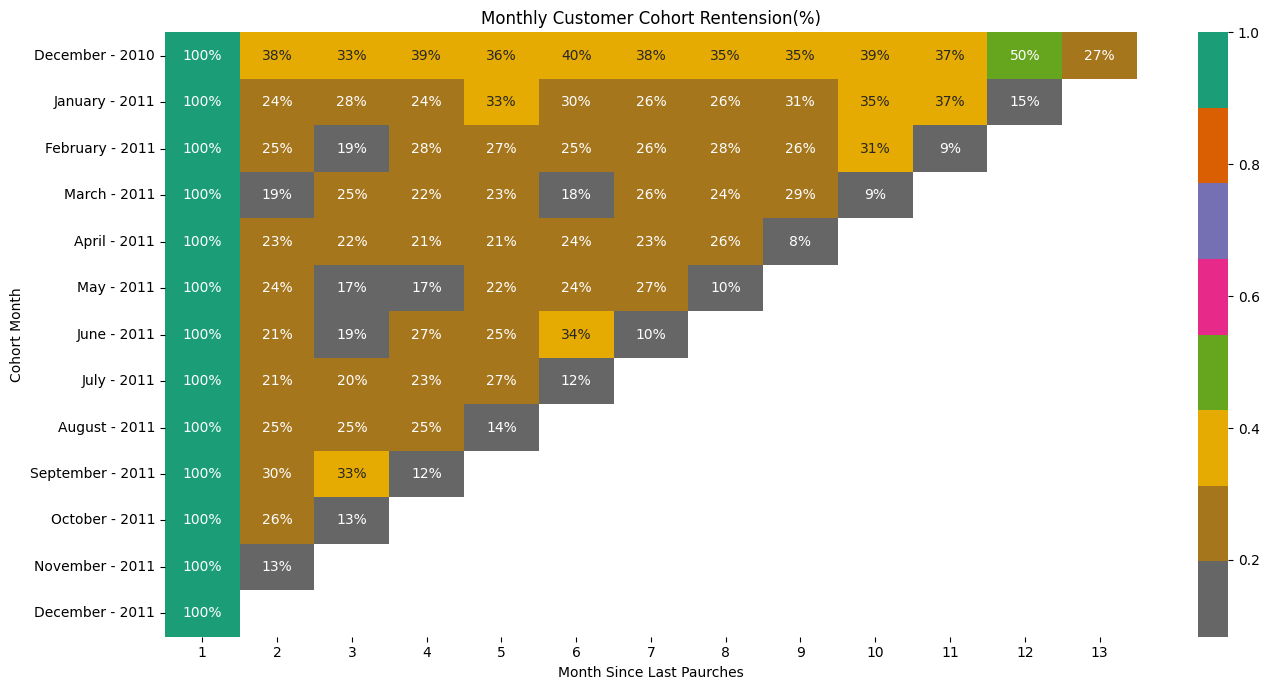

In [93]:
plt.figure(figsize = (14,7))
sns.heatmap(retention,annot = True,fmt = '.0%', cmap = 'Dark2_r')
plt.title('Monthly Customer Cohort Rentension(%)')
plt.xlabel('Month Since Last Paurches')
plt.ylabel('Cohort Month')
plt.tight_layout()
plt.show()

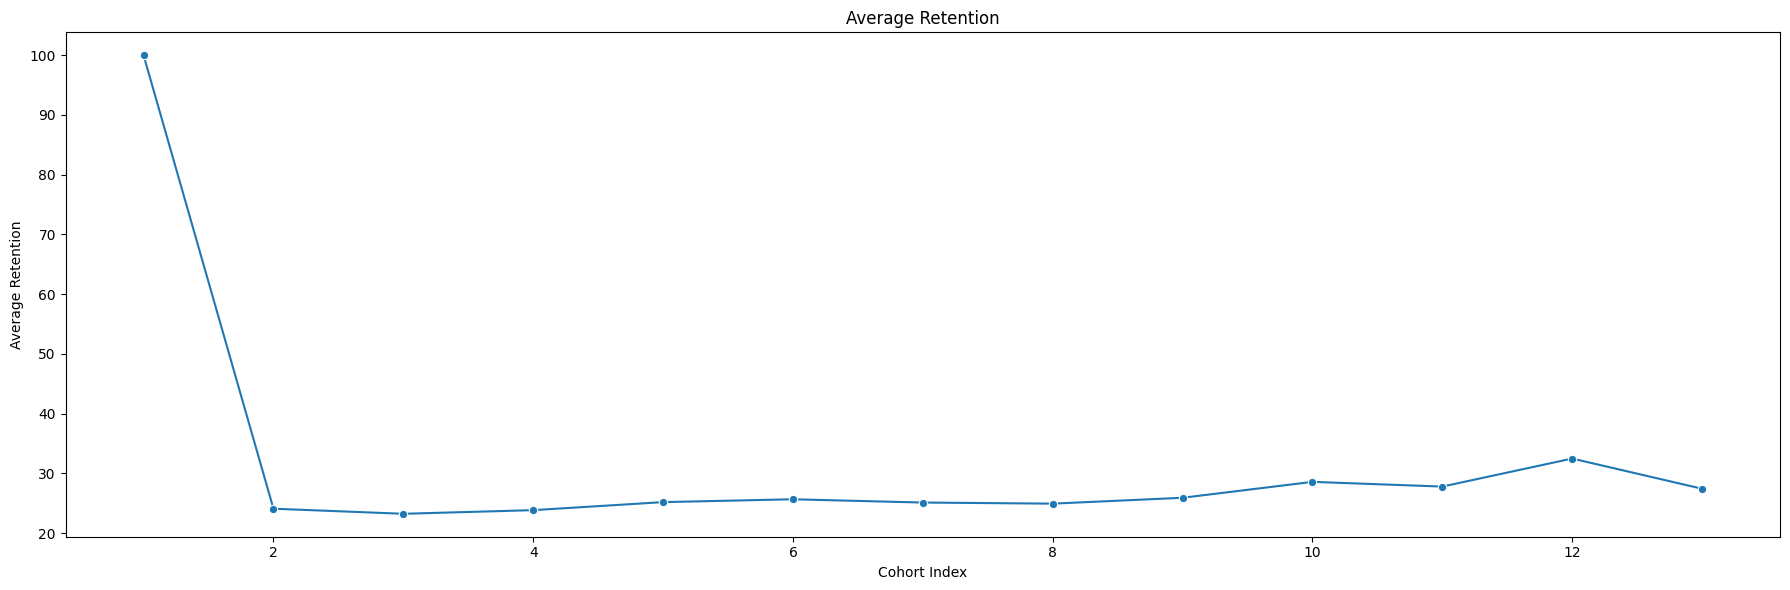

In [95]:
Average_retention = retention.mean()*100
plt.figure(figsize = (18,6))
sns.lineplot(x = Average_retention.index, y = Average_retention.values, marker = 'o' )
plt.ylabel('Average Retention')
plt.xlabel('Cohort Index')
plt.title('Average Retention')
plt.tight_layout()
plt.show()

###  SECTION 2
#### CUSTOMER SEGMENTION USING UNSUPERVISED ML TECHNIQUES

The objective of this project is to understand customer purchasing behaviour by using an unsupervised machine learning clustering algorithm to group customers with similar purchasing patterns.

The segmentation will consider factors such as how recently customers purchased, how frequently they make purchases, their spending behaviour, and the variety of products they buy. The resulting customer groups will help the business understand its customer base and identify opportunities to improve customer engagement and retention.

In [97]:
data['Sales_price'] = data['Quantity'] * data['UnitPrice']

In [98]:
data.head()

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country,InvoiceMonths,CohortMonth,Cohortindex,Sales_price
0,536365,2010-12-01 08:26:00,17850.0,SC1734,Electronics,65,10.23,Egypt,2010-12,2010-12,1,664.95
1,536365,2010-12-01 08:26:00,17850.0,SC2088,Furniture,95,19.61,Mali,2010-12,2010-12,1,1862.95
2,536365,2010-12-01 08:26:00,17850.0,SC3463,Books,78,61.49,Mali,2010-12,2010-12,1,4796.22
3,536365,2010-12-01 08:26:00,17850.0,SC6228,Toys,15,24.73,South Africa,2010-12,2010-12,1,370.95
4,536365,2010-12-01 08:26:00,17850.0,SC2149,Toys,50,38.83,Rwanda,2010-12,2010-12,1,1941.50


In [108]:
CustomerData = data.groupby('CustomerID').agg(
    Monetary = ('Sales_price','sum'),
    Frequency = ('InvoiceDate','nunique'),
    LastPauchase = ('InvoiceDate','max')
    
)
ReferenceDate = data['InvoiceDate'].max() + pd.Timedelta(days = 1)
CustomerData['Recency'] = (ReferenceDate - CustomerData['LastPauchase']).dt.days
CustomerData.head()

,Monetary,Frequency,LastPauchase,Recency
CustomerID,,,,
12346.0,5342.40,2,2011-01-18 10:17:00,326
12347.0,431501.00,7,2011-12-07 15:52:00,2
12348.0,82378.47,4,2011-09-25 13:13:00,75
12349.0,176075.12,1,2011-11-21 09:51:00,19
12350.0,48173.37,1,2011-02-02 16:01:00,310


In [110]:
features = ['Monetary',	'Frequency','Recency']

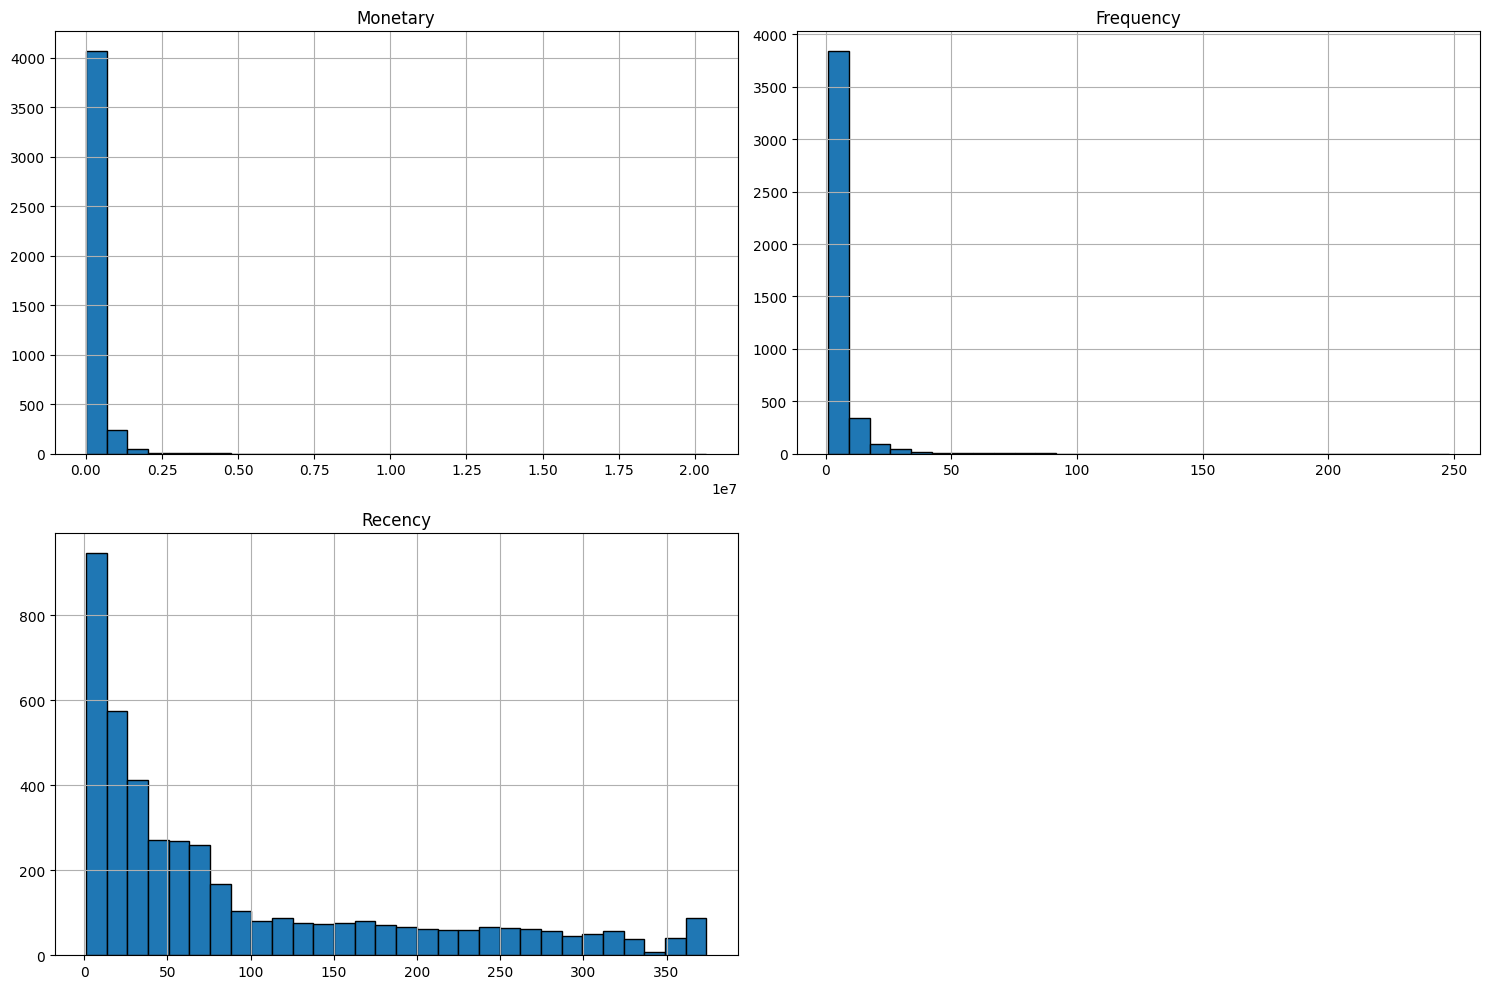

In [114]:
CustomerData[features].hist(figsize = (15,10), bins = 30, edgecolor = 'black' )
plt.tight_layout()
plt.show()

In [115]:
CustomerData[features].skew().sort_values(ascending = False)

Monetary     18.241837
Frequency    11.625654
Recency       1.249665
dtype: float64

In [117]:
X = CustomerData[features].copy()

In [118]:
#Reduce right skewness using log1p
# log1p means log(1 + value); it requires values greater than -1
X_log = np.log1p(X)

In [128]:
#scaled the transformed data
from sklearn.preprocessing import StandardScaler
scaled = StandardScaler()
X_scaled = scaled.fit_transform(X_log)

In [129]:
X_scaled

array([[-2.05264488, -0.46634738,  1.45560892],
       [ 1.04019825,  0.87105278, -1.97486147],
       [-0.12606725,  0.23018392,  0.38857348],
       ...,
       [-0.70886427, -0.0740813 , -1.17151944],
       [ 2.12339875,  1.89885098, -1.6013287 ],
       [ 0.52982513, -0.0740813 , -0.01107755]], shape=(4372, 3))

In [130]:
X_scaled_df = pd.DataFrame(X_scaled,index = CustomerData.index, columns = features)
X_scaled_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Monetary,4372.0,2.356558e-16,1.000114,-6.048416,-0.575651,0.056080,0.683183,3.755410
Frequency,4372.0,-1.690221e-16,1.000114,-1.019215,-1.019215,-0.074081,0.478787,5.558920
Recency,4372.0,-2.291549e-16,1.000114,-2.271351,-0.664667,0.096879,0.855890,1.555763


In [144]:
print("Shape:", X_scaled.shape)
print("NaN values:", np.isnan(X_scaled).sum())
print("Infinite values:", np.isinf(X_scaled).sum())
print("Unique rows:", np.unique(X_scaled, axis=0).shape[0])

Shape: (4372, 3)
NaN values: 0
Infinite values: 0
Unique rows: 4372


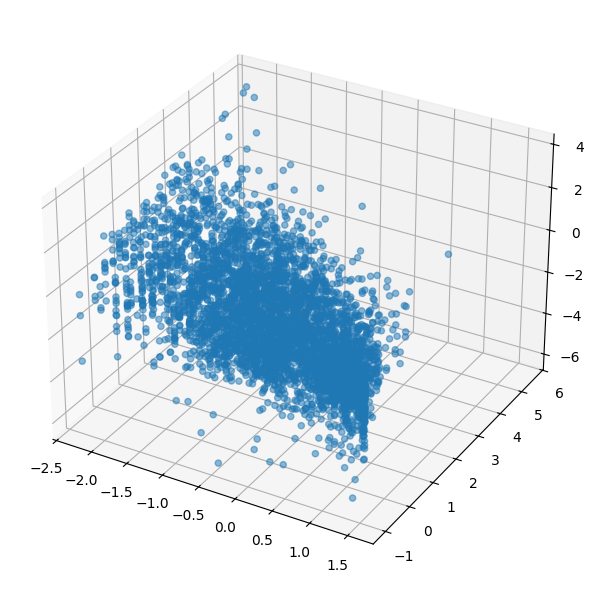

In [131]:
fig = plt.figure(figsize= (10,6))
ax = fig.add_subplot(111, projection = '3d')
ax.scatter(X_scaled_df['Recency'],
           X_scaled_df['Frequency'],
           X_scaled_df['Monetary'],
           alpha = 0.5
          )
plt.tight_layout()
plt.show()

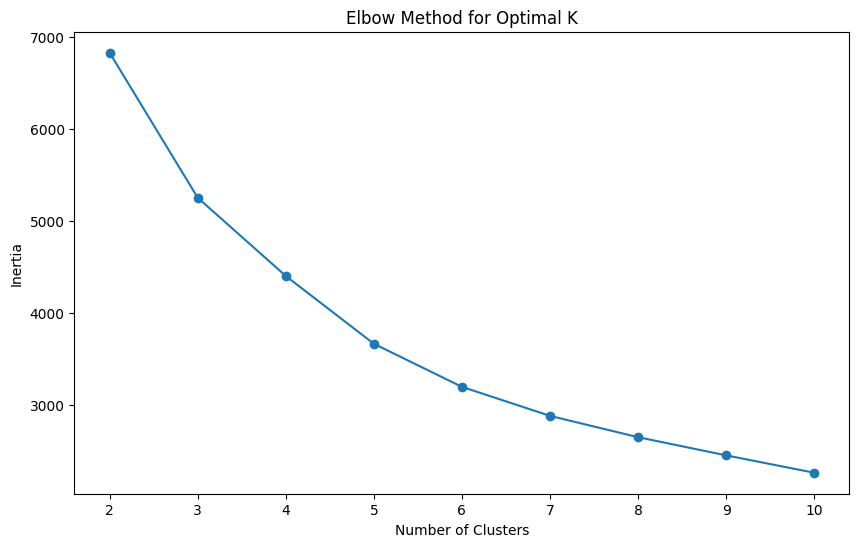

In [140]:
#Elbow Method: test K from 1 to 11
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
inertia = []
for k in range(2,11):
    Kmeans = KMeans(random_state = 42,n_clusters = k, n_init = 10)
    kmeans = Kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize = (10,6))
plt.plot(range(2,11),inertia, marker = 'o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(range(2,11))
plt.show()

In [141]:
#Compare silhouette scores for K = 2 to 10
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

silhouette_results = pd.DataFrame({
    'K': range(2, 11),
    'Silhouette Score': silhouette_scores
})

print(silhouette_results.round(3))


    K  Silhouette Score
0   2             0.410
1   3             0.308
2   4             0.308
3   5             0.286
4   6             0.294
5   7             0.280
6   8             0.282
7   9             0.273
8  10             0.278


K = 2: Silhouette score = 0.410. This gives us two broad customer groups.

K = 4: Silhouette score = 0.308. This gives us four more detailed customer groups.

In [149]:
Kmeans_2 = KMeans(n_clusters = 2, n_init = 10, random_state =42)
CustomerData['Cluster_2'] = Kmeans_2.fit_predict(X_scaled)

Kmeans_4 = KMeans(n_clusters = 4, n_init = 10, random_state =42)
CustomerData['Cluster_4'] = Kmeans_4.fit_predict(X_scaled)


In [150]:
profile_2 = CustomerData.groupby('Cluster_2')[features].mean().round(2)
profile_4 = CustomerData.groupby('Cluster_4')[features].mean().round(2)

print("K = 2: Customer Profiles")
display(profile_2)

print("K = 4: Customer Profiles")
display(profile_4)

K = 2: Customer Profiles


,Monetary,Frequency,Recency
Cluster_2,,,
0,471360.08,9.56,24.31
1,73478.84,1.87,139.45


K = 4: Customer Profiles


,Monetary,Frequency,Recency
Cluster_4,,,
0,107577.84,2.57,16.81
1,235513.33,4.49,77.88
2,45111.73,1.44,184.15
3,771449.24,15.87,12.01


Note on the Choice of K = 2 and K = 4 for Customer Segmentation
We selected both K = 2 and K = 4 for our customer segmentation analysis because they provide two different levels of understanding of customer purchasing behaviour.
The K = 2 model achieved a silhouette score of 0.410, indicating better cluster separation than the K = 4 model, which scored 0.308. It provides a broad view of customers by separating higher-value, more active customers from lower-value, less active customers.
The K = 4 model provides a more detailed view by dividing customers into four groups with different spending levels, purchase frequencies and recency patterns. This helps us identify specific customer segments, including very high-value active customers and customers who may need re-engagement.
Using both models allows us to examine customer behaviour from two perspectives: a broad overview with K = 2 and a more detailed segmentation with K = 4. Although K = 2 has the higher silhouette score, K = 4 offers additional business insights that may support more targeted marketing and customer retention strategies.
Therefore, we retained both models to provide a more complete understanding of customer purchasing behaviour rather than relying on a single clustering solution.

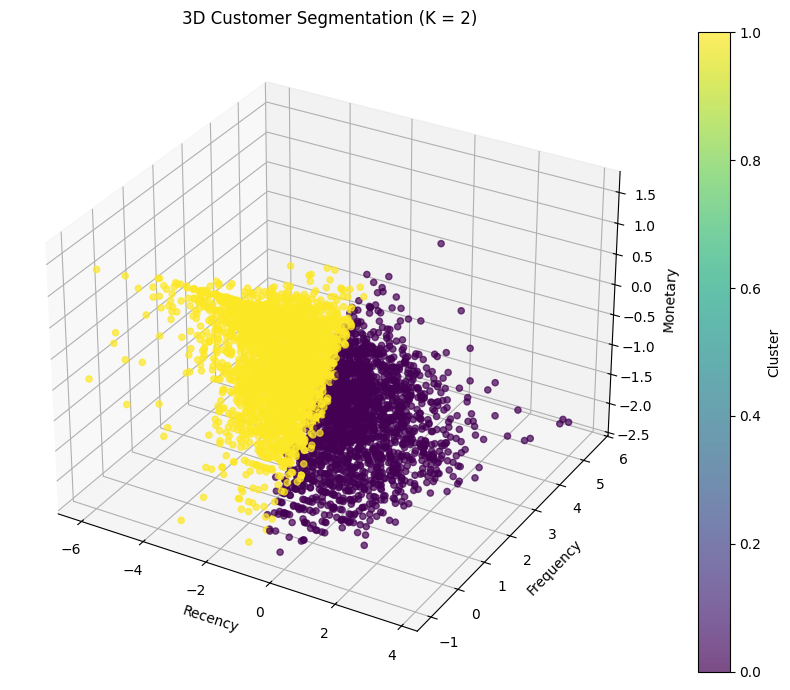

In [161]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    X_scaled[:, 2],
     c=CustomerData['Cluster_2'],
    cmap='viridis',
    alpha=0.7,
    s=20
)

ax.set_title('3D Customer Segmentation (K = 2)')
ax.set_xlabel('Recency')
ax.set_ylabel('Frequency')
ax.set_zlabel('Monetary')

fig.colorbar(scatter, ax=ax, label='Cluster')
plt.tight_layout()
plt.show()

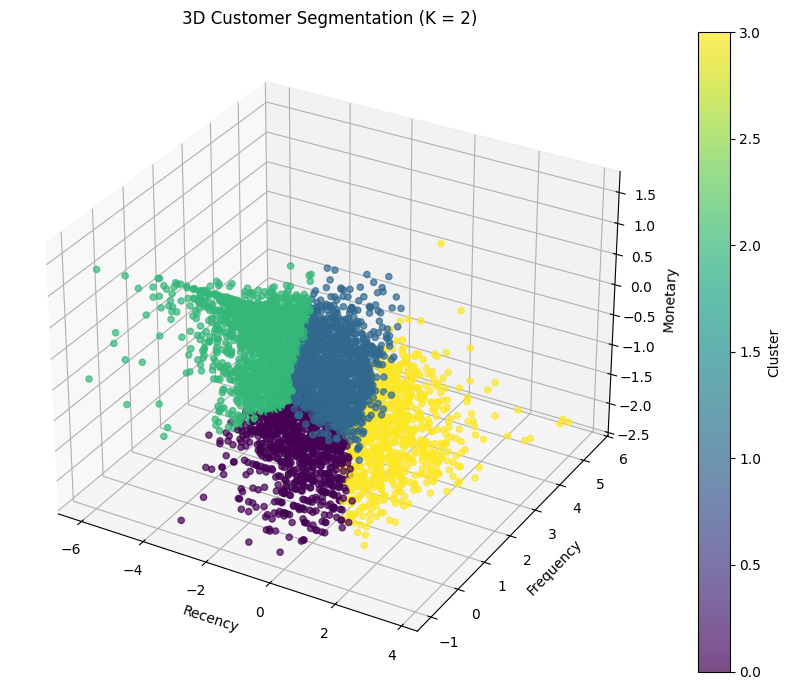

In [158]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    X_scaled[:, 2],
    c=CustomerData['Cluster_4'],
    cmap='viridis',
    alpha=0.7,
    s=20
)

ax.set_title('3D Customer Segmentation (K = 2)')
ax.set_xlabel('Recency')
ax.set_ylabel('Frequency')
ax.set_zlabel('Monetary')

fig.colorbar(scatter, ax=ax, label='Cluster')
plt.tight_layout()
plt.show()

## Customer Distribution by Cluster

In [155]:
features = ['Recency', 'Frequency', 'Monetary']

# K = 2 profile
profile_2 = CustomerData.groupby('Cluster_2')[features].mean().round(2)

print("Customer Profile: K = 2")
display(profile_2)


# K = 4 profile
profile_4 = CustomerData.groupby('Cluster_4')[features].mean().round(2)

print("Customer Profile: K = 4")
display(profile_4)

Customer Profile: K = 2


,Recency,Frequency,Monetary
Cluster_2,,,
0,24.31,9.56,471360.08
1,139.45,1.87,73478.84


Customer Profile: K = 4


,Recency,Frequency,Monetary
Cluster_4,,,
0,16.81,2.57,107577.84
1,77.88,4.49,235513.33
2,184.15,1.44,45111.73
3,12.01,15.87,771449.24


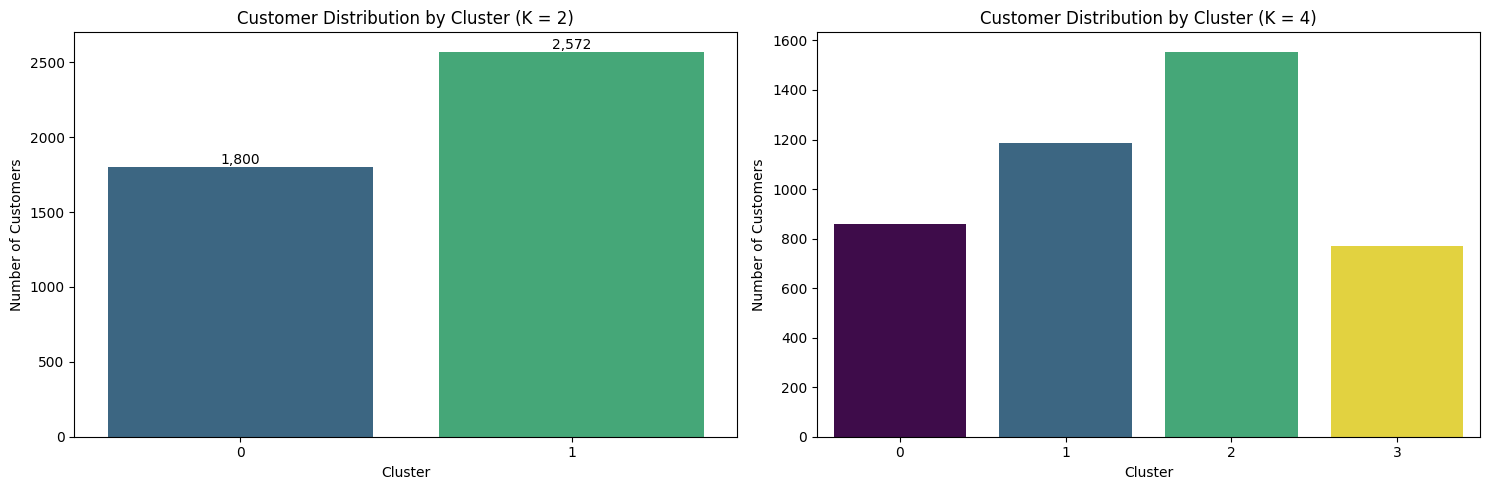

In [169]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize=(15, 5))
ax = ax.flatten()

sns.countplot(
    data=CustomerData,
    x='Cluster_2',
    hue='Cluster_2',
    palette='viridis',
    legend=False,
    ax = ax[0]
)

ax[0].set_title('Customer Distribution by Cluster (K = 2)')
ax[0].set_xlabel('Cluster')
ax[0].set_ylabel('Number of Customers')
for c in ax[0].containers:
    ax[0].bar_label(c, fmt = '{:,.0f}')



sns.countplot(
    data=CustomerData,
    x='Cluster_4',
    hue='Cluster_4',
    palette='viridis',
    legend=False,
    ax = ax[1]
)

ax[1].set_title('Customer Distribution by Cluster (K = 4)')
ax[1].set_xlabel('Cluster')
ax[1].set_ylabel('Number of Customers')
for c in ax[1].containers:
    ax[1].bar_label(c, fmt = '{:,.0f}')

plt.tight_layout()
plt.show()

## Customer Distribution And Cluster Analysis

K-Means clustering was used to group customers based on their purchasing behaviour. The analysis considered **Recency, Frequency and Monetary Value (RFM)**, alongside other behavioural features.

Two clustering options were examined: **K = 2** and **K = 4**.

### 1. Customer Segmentation Using K = 2

Customers were grouped into two segments based on their purchasing behaviour.

| Cluster | Number of Customers | Customer Share | Segment |
|:---:|---:|---:|---|
| 0 | 1,800 | 41.17% | Active |
| 1 | 2,572 | 58.83% | Less Active |
| **Total** | **4,372** | **100%** | |

**Cluster Analysis**

- **Active:** These customers have purchased more recently, make purchases more frequently and have higher monetary value.
- **Less Active:** These customers purchase less frequently, have lower monetary value and have gone longer without making a purchase.

**Business Insight**

The majority of customers (58.83%) belong to the Less Active segment. This suggests an opportunity to encourage repeat purchases through targeted promotions and customer engagement campaigns. Retention activities could also help maintain the purchasing activity of Active customers.

### 2. Customer Segmentation Using K = 4

The four-cluster model provides a more detailed view of customer purchasing behaviour.

| Cluster | Number of Customers | Customer Share | Segment |
|:---:|---:|---:|---|
| 0 | 859 | 19.65% | Active |
| 1 | 1,186 | 27.13% | At-Risk |
| 2 | 1,555 | 35.57% | Dormant |
| 3 | 772 | 17.66% | Champions |
| **Total** | **4,372** | **100%** | |

**Cluster Analysis**

- **Active:** Customers who have purchased recently but show lower purchasing frequency and monetary value than Champions.
- **At-Risk:** Customers with relatively high purchasing frequency and spending, but whose last purchases were some time ago.
- **Dormant:** The largest customer group, with the lowest purchasing frequency and monetary value, and the longest time since their last purchase.
- **Champions:** Customers with the highest purchasing frequency and monetary value, and the lowest recency, indicating recent and consistent purchasing activity.

**Business Insights**

- **Champions:** Maintain engagement through loyalty programmes and personalised offers.
- **At-Risk:** Encourage these customers to return through targeted promotions and follow-up campaigns.
- **Dormant:** Consider re-engagement campaigns to encourage repeat purchases.
- **Active:** Nurture these customers to increase their purchasing frequency and overall value.

### 3. Comparison of the Two Clustering Models

The K = 2 model provides a broad distinction between Active and Less Active customers. The K = 4 model gives a more detailed understanding by identifying four different customer groups.

The four-cluster model provides more specific insights that can support targeted customer engagement and retention strategies.

**Conclusion**

The clustering analysis shows that customers have different purchasing patterns and levels of engagement. These segments can help the business identify opportunities to retain valuable customers, encourage repeat purchases and re-engage customers who have become less active.

## Cluster profile comparison

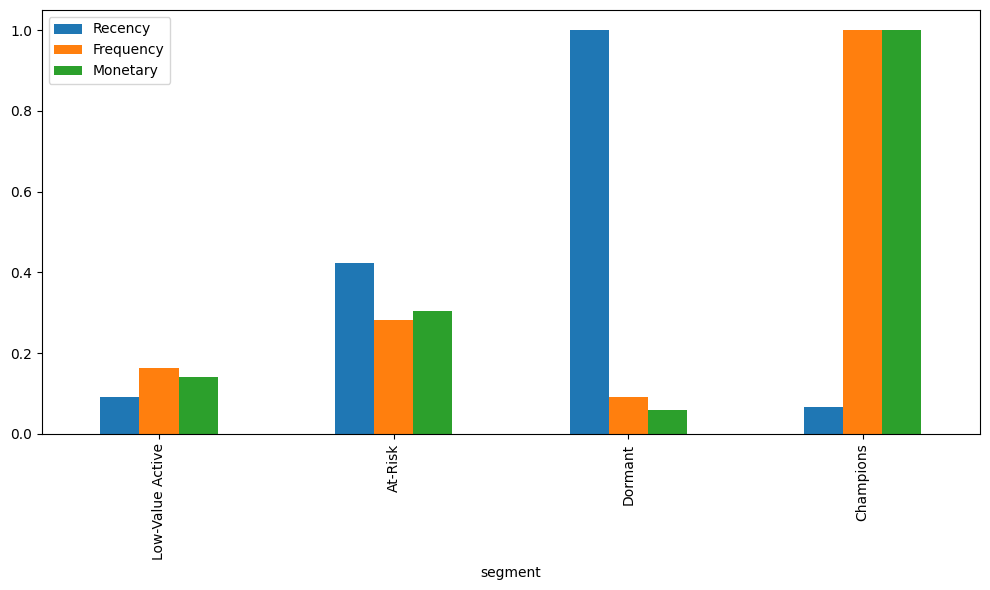

In [202]:
cluster_name = {
    0: 'Low-Value Active',
    1: 'At-Risk',
    2: 'Dormant',
    3: 'Champions'
}
  
profile_4['segment'] = profile_4.index.map(cluster_name)
df_plot = profile_4.copy()
df_plot[['Recency', 'Frequency', 'Monetary']] = df_plot[
    ['Recency', 'Frequency', 'Monetary']
].apply(lambda x:x/x.max())

df_plot.set_index('segment')[['Recency', 'Frequency', 'Monetary']].plot(kind = 'bar',figsize = (10,6))
plt.tight_layout()
plt.show()


This chart compares the average Recency, Frequency and Monetary values across the four customer segments. The values have been normalised between 0 and 1, making it easier to compare features with different measurement scales.
Insights from the chart
- Low Value Active: Have relatively low recency and the highest frequency and monetary values among the four segments. These customers purchase regularly and contribute strongly to customer spending.
- At Risk: Have higher recency than Loyal Regulars, alongside moderate frequency and monetary values. This suggests that they have purchased in the past but have not purchased recently.
- Dormant: Have the highest recency value but very low frequency and monetary values. This suggests that they have not purchased recently and have limited purchasing activity in the dataset.
- Champions: Have the highest frequency and monetary values, but very low recency. These customers are highly active and valuable to the business.

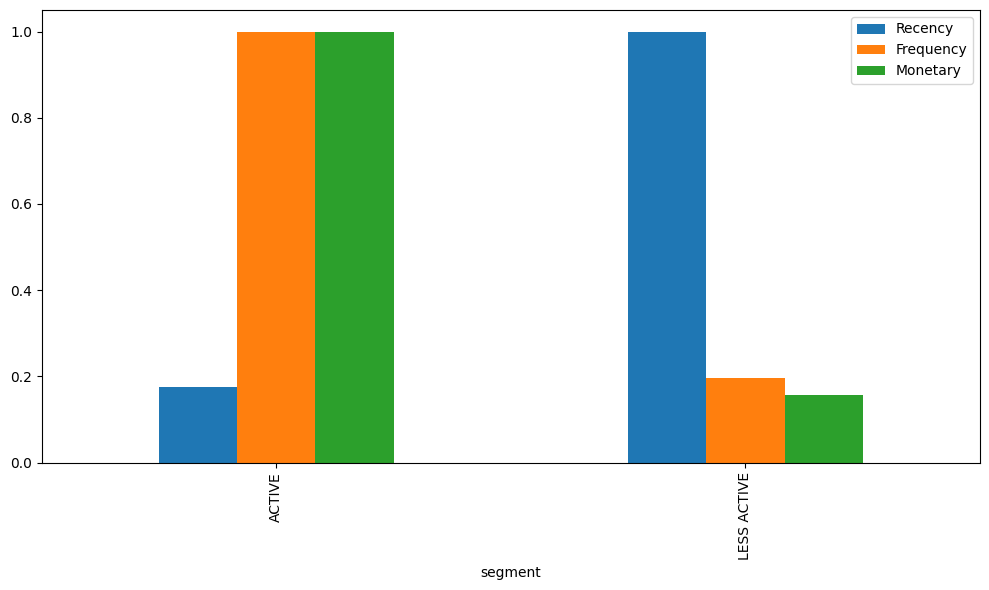

In [200]:
cluster_name = {
    0: 'ACTIVE',
    1: 'LESS ACTIVE'
}
profile_2['segment'] = profile_2.index.map(cluster_name)
df_plot = profile_2.copy()
df_plot[['Recency', 'Frequency', 'Monetary']] = df_plot[
    ['Recency', 'Frequency', 'Monetary']
].apply(lambda x:x/x.max())

df_plot.set_index('segment')[['Recency', 'Frequency', 'Monetary']].plot(kind = 'bar',figsize = (10,6))
plt.tight_layout()
plt.show()

The K-means clustering model grouped customers into two segments: Active and Less Active.

- **Active Customers (Cluster 0):** These customers have lower recency values, indicating that they have purchased more recently. Their purchasing activity is relatively higher, suggesting stronger engagement with the business.
- **Less Active Customers (Cluster 1):** These customers have higher recency values, meaning they have not purchased for a longer period. Their purchasing activity is relatively lower, indicating weaker engagement with the business.

**Business Insight:** The results show two distinct groups based on customer purchasing behaviour. The business could focus on maintaining engagement with Active customers through loyalty initiatives, while targeted promotions and re-engagement campaigns could encourage Less Active customers to make further purchases.